# Box sizing

An online shop ships a few hundred orders a day from one warehouse. Its supplier's catalogue has 20
carton sizes, and the packing station has shelf space for only a handful of them. Every order has
to leave in one of the cartons on the shelf, and a small order in a big carton ships mostly air:
filler, freight billed by volume, and a van that fills up early. The question is **which few sizes to
stock**.

The input is what the warehouse already knows: the packed size of last quarter's shipments, and how
often each size went out.

In this notebook you will:

1. describe the cartons and the shipments as Python objects,
2. solve it and read which sizes to stock,
3. check the result yourself, without trusting the solver's score,
4. see what each additional size on the shelf is worth,
5. replace the limit by a price per size, and keep a carton that is already on the shelf,
6. add this quarter's shipments and restart the search from last quarter's sizes.

Requires Python 3.11+ and an optimaru release that has `optimaru.box_sizing` (the first one after
0.8.0): `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

from optimaru import box_sizing as bs
from optimaru.box_sizing import constraints as rules
from optimaru.box_sizing.models import BoxModel, BoxSizingProblemModel, ParcelModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the cartons and the shipments

Three objects make up a problem.

| Object | What it holds |
| --- | --- |
| `BoxModel` | a candidate carton: id, inner `length`, `width`, `height`; optionally the heaviest parcel it carries (`max_weight`), what one costs (`cost`) and whether it is already stocked and staying (`required`) |
| `ParcelModel` | the packed content of one shipment by its bounding size, its `weight`, and `quantity`: how many shipments had that size |
| `BoxSizingProblemModel` | the boxes, the parcels and `max_box_types`: how many distinct boxes may be in use |

Lengths and weights are whole numbers in whatever unit you use. Here they are millimetres and grams,
so a volume is in mm³; the charts show litres.

A parcel **fits** a box when its three sides, sorted, are each at most the box's sorted sides: it may be
turned any way. Arranging the items of an order inside a carton is another problem; this one takes each
shipment's packed size as given.

Here is a fictional shop. Its orders come in a few typical shapes (a book, a shoe box, a small
appliance), each with some spread, and small orders are far more common than large ones.

In [2]:
CATALOGUE = [  # inner length, width, height in mm
    (160, 110, 60), (200, 150, 100), (220, 160, 60), (250, 200, 100), (260, 180, 150), (300, 200, 120),
    (300, 230, 180), (320, 240, 100), (330, 250, 150), (350, 300, 150), (380, 280, 230), (400, 300, 200),
    (430, 320, 180), (450, 350, 250), (480, 380, 340), (500, 400, 300), (520, 380, 260), (550, 420, 350),
    (600, 400, 400), (600, 450, 400),
]
SHAPES = [  # typical packed orders, most common first
    (150, 100, 40), (190, 140, 80), (240, 170, 60), (260, 200, 130), (310, 220, 90), (330, 240, 190),
    (390, 290, 170), (440, 330, 230), (520, 390, 310),
]
SHELF = 5

boxes = [
    BoxModel(id=f"C{i + 1:02d}", length=l, width=w, height=h, max_weight=20_000 if l * w * h < 20e6 else 30_000)
    for i, (l, w, h) in enumerate(CATALOGUE)
]


def shipments(count, seed, prefix="P"):
    rng = np.random.default_rng(seed)
    parcels = []
    for i in range(count):
        shape = SHAPES[min(int(rng.exponential(2.2)), len(SHAPES) - 1)]
        sides = [int(min(limit, max(20, round(side * rng.uniform(0.75, 1.2) / 5) * 5)))
                 for side, limit in zip(shape, CATALOGUE[-1])]
        litres = sides[0] * sides[1] * sides[2] / 1e6
        parcels.append(ParcelModel(
            id=f"{prefix}{i + 1:03d}", length=sides[0], width=sides[1], height=sides[2],
            weight=int(min(19_000, max(100, litres * rng.uniform(120, 420)))),
            quantity=int(max(1, rng.pareto(1.3) * 4)),
        ))
    return parcels


problem = BoxSizingProblemModel(boxes=boxes, parcels=shipments(150, seed=7), max_box_types=SHELF)


def litres(thing):
    return thing.length * thing.width * thing.height / 1e6


total = sum(p.quantity for p in problem.parcels)
print(f"{len(problem.boxes)} candidate cartons, {len(problem.parcels)} parcel sizes, {total:,} shipments")
print(f"shelf space for {problem.max_box_types} sizes")
print("the three most shipped:")
for p in sorted(problem.parcels, key=lambda p: -p.quantity)[:3]:
    print(f"  {p.id}: {p.length} x {p.width} x {p.height} mm, {p.weight} g, {p.quantity} shipments")

20 candidate cartons, 150 parcel sizes, 1,255 shipments
shelf space for 5 sizes
the three most shipped:
  P019: 150 x 110 x 45 mm, 122 g, 229 shipments
  P123: 260 x 135 x 65 mm, 486 g, 86 shipments
  P138: 155 x 85 x 30 mm, 130 g, 58 shipments


Each dot is one parcel size, placed by its longest side and its volume and sized by how often it shipped.
The squares are the cartons of the catalogue. A carton can only take the parcels below and to the left of
it, and even then only when the two other sides fit.

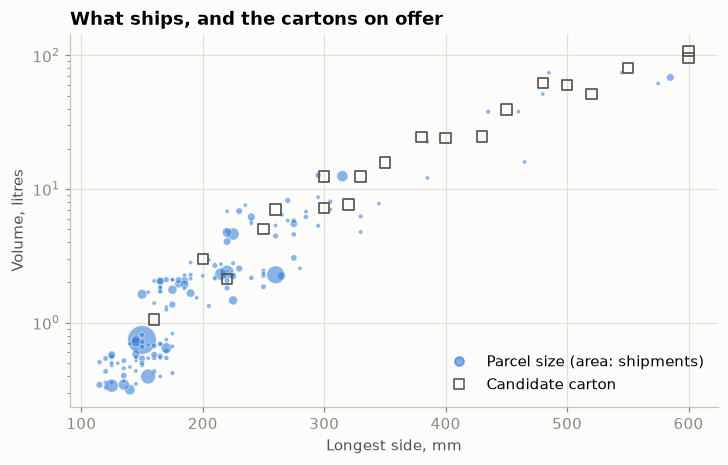

In [3]:
fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.scatter([max(p.length, p.width, p.height) for p in problem.parcels], [litres(p) for p in problem.parcels],
           s=[6 + 1.5 * p.quantity for p in problem.parcels], color=COLORS[0], alpha=0.55, edgecolor="#fcfcfb",
           linewidth=0.5, zorder=2)
ax.scatter([max(b.length, b.width, b.height) for b in boxes], [litres(b) for b in boxes], marker="s", s=46,
           facecolor="none", edgecolor=INK, linewidth=1.1, zorder=3)
ax.set(title="What ships, and the cartons on offer", xlabel="Longest side, mm", ylabel="Volume, litres",
       yscale="log")
ax.grid(True)
ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="", color=COLORS[0], alpha=0.6, label="Parcel size (area: shipments)"),
    Line2D([], [], marker="s", linestyle="", markerfacecolor="none", color=INK, label="Candidate carton"),
], loc="lower right")
plt.show()

## 2. Solve it

`bs.solve` takes the model and returns a new, solved one; the model you passed in is left as it was. On
the result, every parcel has the `box` it ships in, every box has `parcels` (the shipments in it), and the
score has two levels, compared in order:

- **hard**: minus (the length by which parcels exceed their box + the weight above a box's `max_weight` +
  the number of box types above `max_box_types`). `0` means the plan is feasible.
- **soft**: minus (the air shipped + the cost of the boxes). The air is `quantity × (box volume − parcel
  volume)`, summed over the parcels; these cartons have no `cost`, so the soft score is the air alone,
  in mm³.

`box_types_used`, `void_volume` and `fill_ratio` (parcel volume ÷ box volume, over all shipments) are
filled in as well.

In [4]:
solved = bs.solve(problem, time_limit_seconds=2, random_seed=42)

stocked = [box for box in solved.boxes if box.parcels]
print("feasible  :", solved.score_hard == 0)
print("score     :", solved.score_hard, "/", solved.score_soft)
print("sizes     :", solved.box_types_used, "of", len(solved.boxes))
print(f"air       : {solved.void_volume / 1e6:,.0f} litres over {total:,} shipments")
print(f"fill ratio: {solved.fill_ratio:.1%}")
for box in stocked:
    print(f"  {box.id}  {box.length} x {box.width} x {box.height} mm  {litres(box):5.1f} l  {box.parcels:5d} shipments")

feasible  : True
score     : 0 / -5232031125.0
sizes     : 5 of 20
air       : 5,232 litres over 1,255 shipments
fill ratio: 41.8%
  C01  160 x 110 x 60 mm    1.1 l    523 shipments
  C04  250 x 200 x 100 mm    5.0 l    422 shipments
  C06  300 x 200 x 120 mm    7.2 l    171 shipments
  C12  400 x 300 x 200 mm   24.0 l    118 shipments
  C20  600 x 450 x 400 mm  108.0 l     21 shipments


### The shelf

Each stocked carton gets a color that stays with it for the rest of the notebook. The left chart shows how
many shipments leave in each carton, the right one what those shipments fill of it. The smallest cartons
carry most of the shipments; the largest one is on the shelf because a few orders fit nothing else.

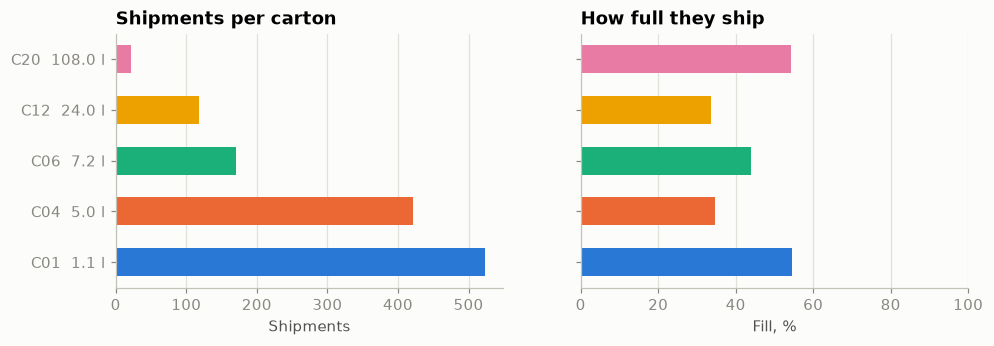

In [5]:
BOX_COLOR = {box.id: COLORS[slot % len(COLORS)] for slot, box in enumerate(stocked)}
box_by_id = {box.id: box for box in solved.boxes}


def fill_of(result, box_id):
    inside = [p for p in result.parcels if p.box == box_id]
    shipped = sum(p.quantity * litres(p) for p in inside)
    return shipped / (sum(p.quantity for p in inside) * litres(box_by_id[box_id]))


fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
names = [f"{box.id}  {litres(box):.1f} l" for box in stocked]
colors = [BOX_COLOR[box.id] for box in stocked]
axes[0].barh(names, [box.parcels for box in stocked], height=0.55, color=colors)
axes[0].set(title="Shipments per carton", xlabel="Shipments")
axes[1].barh(names, [100 * fill_of(solved, box.id) for box in stocked], height=0.55, color=colors)
axes[1].set(title="How full they ship", xlabel="Fill, %", xlim=(0, 100))
for ax in axes:
    ax.invert_yaxis()
    ax.grid(True, axis="x")
plt.show()

The same plan on the picture of section 1: every parcel size takes the color of its carton. A parcel goes to
the smallest stocked carton that takes it, so the colors form bands, and a parcel with one long side can
sit in a band above parcels of twice its volume.

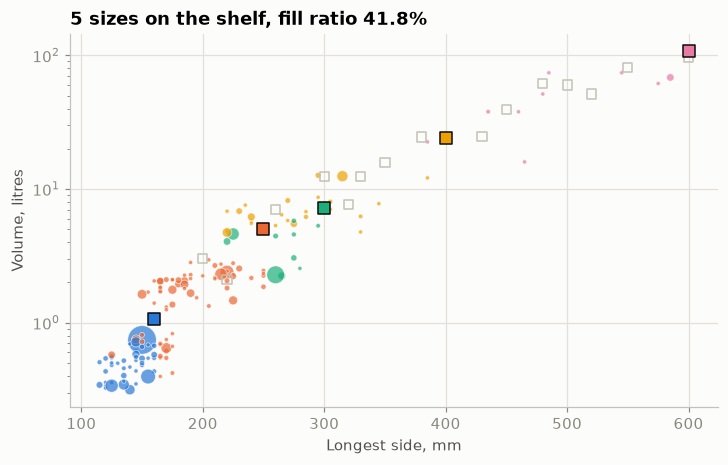

In [6]:
def color_of(box_id):
    # A carton that was not on the shelf before gets the next free color.
    if box_id not in BOX_COLOR:
        BOX_COLOR[box_id] = COLORS[len(BOX_COLOR) % len(COLORS)]
    return BOX_COLOR[box_id]


def draw_plan(ax, result, title):
    ax.scatter([max(p.length, p.width, p.height) for p in result.parcels], [litres(p) for p in result.parcels],
               s=[6 + 1.5 * p.quantity for p in result.parcels],
               color=[color_of(p.box) for p in result.parcels], alpha=0.7, edgecolor="#fcfcfb",
               linewidth=0.5, zorder=2)
    for box in result.boxes:
        if box.parcels:
            ax.scatter(max(box.length, box.width, box.height), litres(box), marker="s", s=70,
                       color=color_of(box.id), edgecolor="#0b0b0b", linewidth=1, zorder=4)
        else:
            ax.scatter(max(box.length, box.width, box.height), litres(box), marker="s", s=36, facecolor="none",
                       edgecolor="#c3c2b7", linewidth=1, zorder=3)
    ax.set(title=title, xlabel="Longest side, mm", yscale="log")
    ax.grid(True)


fig, ax = plt.subplots(figsize=(7.6, 4.4))
draw_plan(ax, solved, f"{solved.box_types_used} sizes on the shelf, fill ratio {solved.fill_ratio:.1%}")
ax.set_ylabel("Volume, litres")
plt.show()

## 3. Check the result yourself

The `box` of every parcel is the whole answer, so everything can be recomputed from it with no solver code:
every parcel fits its box when turned the right way, no parcel is too heavy, no more than five sizes are in
use, and the soft score is minus the air.

In [7]:
def fits(parcel, box):
    sides = zip(sorted((parcel.length, parcel.width, parcel.height)), sorted((box.length, box.width, box.height)))
    return all(p <= b for p, b in sides) and (box.max_weight is None or parcel.weight <= box.max_weight)


air = sum(p.quantity * (litres(box_by_id[p.box]) - litres(p)) for p in solved.parcels)
shipped = sum(p.quantity * litres(p) for p in solved.parcels)

print("every parcel has a box   :", all(p.box is not None for p in solved.parcels))
print("every parcel fits its box:", all(fits(p, box_by_id[p.box]) for p in solved.parcels))
print("sizes in use             :", len({p.box for p in solved.parcels}), "of at most", solved.max_box_types)
print(f"air recomputed           : {air * 1e6:,.0f} mm³")
print(f"soft score from solver   : {solved.score_soft:,.0f}")
print(f"fill ratio recomputed    : {shipped / (shipped + air):.1%}")

every parcel has a box   : True
every parcel fits its box: True
sizes in use             : 5 of at most 5
air recomputed           : 5,232,031,125 mm³
soft score from solver   : -5,232,031,125
fill ratio recomputed    : 41.8%


## 4. What is one more size worth?

Shelf space is the real constraint, so the useful question is what each additional size buys. This solves
the same shipments for one to ten sizes. The row at five is the plan of section 2.

With one size everything ships in the carton that takes the largest order. The first few sizes cut the air
steeply, and after that each one buys less: the curve is what you take to the person who owns the shelf.

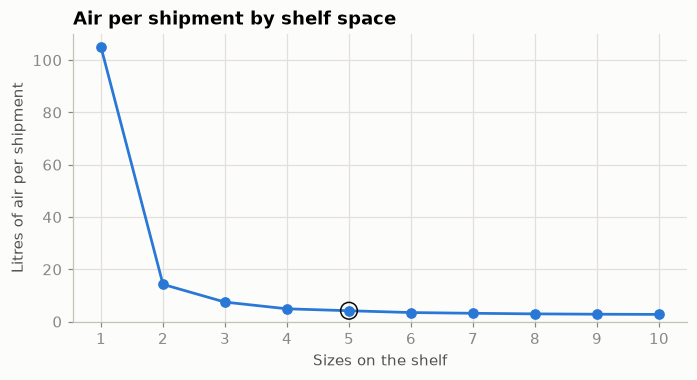

 1 sizes: fill  2.8%, 105.00 l of air per shipment
 2 sizes: fill 17.4%, 14.25 l of air per shipment
 3 sizes: fill 28.6%,  7.47 l of air per shipment
 4 sizes: fill 37.9%,  4.91 l of air per shipment
 5 sizes: fill 41.8%,  4.17 l of air per shipment
 6 sizes: fill 46.3%,  3.47 l of air per shipment
 7 sizes: fill 48.4%,  3.19 l of air per shipment
 8 sizes: fill 50.2%,  2.97 l of air per shipment
 9 sizes: fill 51.4%,  2.84 l of air per shipment
10 sizes: fill 52.0%,  2.77 l of air per shipment


In [8]:
by_shelf = {SHELF: solved}
for shelf in range(1, 11):
    if shelf != SHELF:
        by_shelf[shelf] = bs.solve(problem.model_copy(update={"max_box_types": shelf}), time_limit_seconds=1,
                                   random_seed=42)

shelves = sorted(by_shelf)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(shelves, [by_shelf[s].void_volume / 1e6 / total for s in shelves], color=COLORS[0], marker="o",
        linewidth=1.8)
ax.scatter([SHELF], [solved.void_volume / 1e6 / total], s=120, facecolor="none", edgecolor="#0b0b0b", zorder=3)
ax.set(title="Air per shipment by shelf space", xlabel="Sizes on the shelf", ylabel="Litres of air per shipment",
       xticks=shelves, ylim=(0, None))
ax.grid(True)
plt.show()

for shelf in shelves:
    result = by_shelf[shelf]
    print(f"{shelf:2d} sizes: fill {result.fill_ratio:5.1%}, {result.void_volume / 1e6 / total:5.2f} l of air per shipment")

## 5. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and `solve` takes the list
you want through `constraints=`. Only listed constraints are scored.

In [9]:
for row in bs.constraint_info():
    print(f"{row.name:20s} {row.default_level}, weight {row.default_weight:g}")

parcel_fit_cost      hard, weight 1
box_weight_cost      hard, weight 1
void_volume_cost     soft, weight 1
box_cost             soft, weight 1
box_type_limit_cost  hard, weight 1
box_type_cost        soft, weight 0


### A price per size instead of a limit

The last one, `box_type_cost`, has weight 0: it counts the sizes in use and scores nothing until you give it
a weight. That weight is the **fixed cost of stocking one more size**, in the units of the soft score. So
instead of saying "five sizes", you can say what a size has to save before it earns its place, and let the
number of sizes follow.

Here the limit is taken away, and a size has to save 500, 2,000 or 8,000 litres of air over the quarter.

In [10]:
no_limit = problem.model_copy(update={"max_box_types": None})

for saving_litres in (500, 2_000, 8_000):
    picks = [
        rules.BoxTypeCost(weight=saving_litres * 1e6) if spec.name == "box_type_cost" else spec
        for spec in rules.get_constraints()
    ]
    priced = bs.solve(no_limit, time_limit_seconds=1, random_seed=42, constraints=picks)
    print(f"a size must save {saving_litres:5,} l: {priced.box_types_used:2d} sizes, fill {priced.fill_ratio:.1%}, "
          f"{priced.void_volume / 1e6 / total:.2f} l of air per shipment")

a size must save   500 l:  6 sizes, fill 46.3%, 3.47 l of air per shipment


a size must save 2,000 l:  4 sizes, fill 37.9%, 4.91 l of air per shipment


a size must save 8,000 l:  3 sizes, fill 28.6%, 7.47 l of air per shipment


Scores from different weights are not comparable, so compare the sizes, the fill ratio and the air.

### A carton that stays

The warehouse has just bought a year's supply of `C08`, a flat carton. Marking it `required` keeps it on the
shelf: it counts as one of the five whether or not anything ships in it, so the solver plans the other four
around it.

free choice : ['C01', 'C04', 'C06', 'C12', 'C20'] fill 41.8%
C08 required: ['C01', 'C06', 'C08', 'C12', 'C20'] fill 40.2%
keeping C08 costs 0.28 l of air per shipment


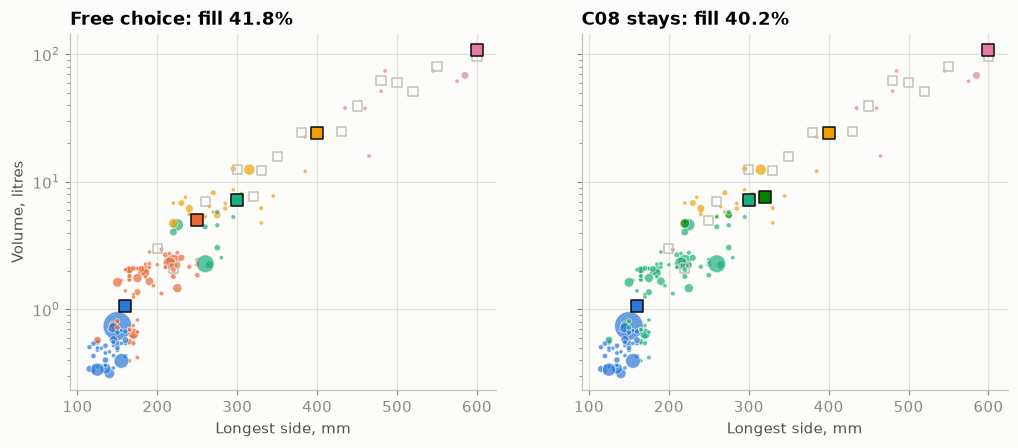

In [11]:
keep = problem.model_copy(deep=True)
next(box for box in keep.boxes if box.id == "C08").required = True
kept = bs.solve(keep, time_limit_seconds=2, random_seed=42)

print("free choice :", [box.id for box in solved.boxes if box.parcels], f"fill {solved.fill_ratio:.1%}")
print("C08 required:", [box.id for box in kept.boxes if box.parcels or box.required], f"fill {kept.fill_ratio:.1%}")
print(f"keeping C08 costs {(kept.void_volume - solved.void_volume) / 1e6 / total:.2f} l of air per shipment")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
draw_plan(axes[0], solved, f"Free choice: fill {solved.fill_ratio:.1%}")
draw_plan(axes[1], kept, f"C08 stays: fill {kept.fill_ratio:.1%}")
axes[0].set_ylabel("Volume, litres")
plt.show()

A carton that was not on the shelf in section 2 gets the next free color, and keeps it from then on.

## 6. Keep working from an existing plan

### A new quarter

Three months later there are 40 new parcel sizes, among them a product line of flat items the size of a
picture frame. The shelf
should not be turned over for nothing, so the search starts from the current plan rather than from scratch.

`with_initial_solution` takes the new problem and the old solution. Parcels are matched by id, and a parcel
the solution does not mention is placed by the construction around the sizes already in use. The copy it
returns has `warm_start` set, which is what tells `solve` to start from the boxes on the parcels: a plain
solve ignores them.

The restart uses a new `random_seed`, so that it does not repeat the search that produced the plan.

parcels without a box before the restart: 40


old sizes, new shipments: fill 28.5%
after the restart       : fill 39.5%
sizes kept   : ['C06', 'C12', 'C20']
sizes dropped: ['C01', 'C04']
sizes added  : ['C03', 'C08']


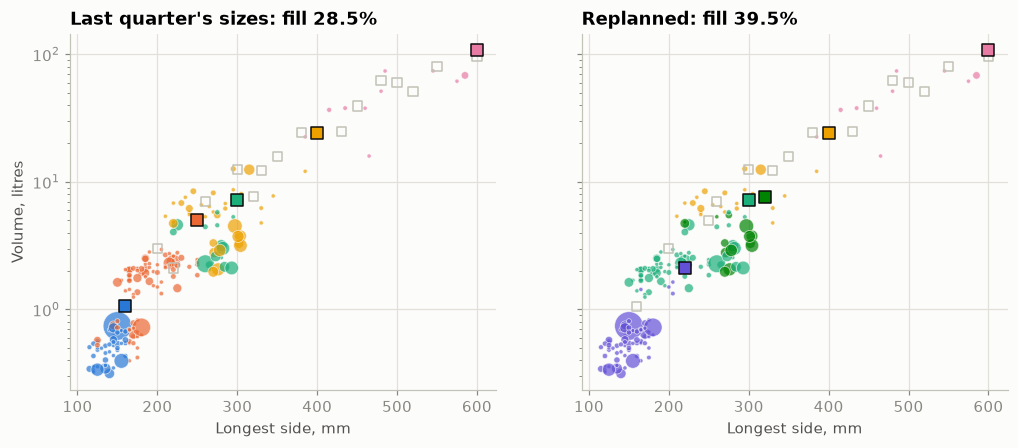

In [12]:
rng = np.random.default_rng(23)
new_line = [
    ParcelModel(id=f"N{i + 1:02d}", length=int(rng.integers(270, 320)), width=int(rng.integers(190, 240)),
                height=int(rng.integers(30, 70)), weight=int(rng.integers(600, 2500)),
                quantity=int(rng.integers(15, 60)))
    for i in range(15)
]
larger = problem.model_copy(update={"parcels": [*problem.parcels, *new_line, *shipments(25, seed=31, prefix="Q")]})

seeded = bs.with_initial_solution(larger, solved)
print("parcels without a box before the restart:", sum(p.box is None for p in seeded.parcels))

carried = bs.solve(seeded, time_limit_seconds=0)             # the old sizes, the new parcels placed in them
replanned = bs.solve(seeded, time_limit_seconds=2, random_seed=43)

before = {box.id for box in solved.boxes if box.parcels}
after = {box.id for box in replanned.boxes if box.parcels}
print(f"old sizes, new shipments: fill {carried.fill_ratio:.1%}")
print(f"after the restart       : fill {replanned.fill_ratio:.1%}")
print("sizes kept   :", sorted(before & after))
print("sizes dropped:", sorted(before - after))
print("sizes added  :", sorted(after - before))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
draw_plan(axes[0], carried, f"Last quarter's sizes: fill {carried.fill_ratio:.1%}")
draw_plan(axes[1], replanned, f"Replanned: fill {replanned.fill_ratio:.1%}")
axes[0].set_ylabel("Volume, litres")
plt.show()

`time_limit_seconds=0` runs no search: it returns the seed, completed by the construction. That is the left
chart, and the honest baseline for the right one: what the old shelf does with the new shipments.

### How good is a plan?

On an instance of this size the answer can be checked. `time_limit_seconds=0` on the original problem gives
the greedy construction (add the size that saves the most, one at a time), and the search then looks for a
better set of sizes by closing, opening and swapping them. Solving from several seeds shows whether the
search keeps ending in the same place.

In [13]:
greedy = bs.solve(problem, time_limit_seconds=0)
runs = [bs.solve(problem, time_limit_seconds=1, random_seed=seed) for seed in range(5)]

print(f"greedy construction: {greedy.void_volume / 1e6 / total:.3f} l of air per shipment, "
      f"sizes {[box.id for box in greedy.boxes if box.parcels]}")
for seed, run in enumerate(runs):
    print(f"search, seed {seed}     : {run.void_volume / 1e6 / total:.3f} l of air per shipment, "
          f"sizes {[box.id for box in run.boxes if box.parcels]}")

greedy construction: 4.179 l of air per shipment, sizes ['C01', 'C04', 'C09', 'C12', 'C20']
search, seed 0     : 4.169 l of air per shipment, sizes ['C01', 'C04', 'C06', 'C12', 'C20']
search, seed 1     : 4.169 l of air per shipment, sizes ['C01', 'C04', 'C06', 'C12', 'C20']
search, seed 2     : 4.169 l of air per shipment, sizes ['C01', 'C04', 'C06', 'C12', 'C20']
search, seed 3     : 4.169 l of air per shipment, sizes ['C01', 'C04', 'C06', 'C12', 'C20']
search, seed 4     : 4.169 l of air per shipment, sizes ['C01', 'C04', 'C06', 'C12', 'C20']


The guide's [Search](https://github.com/optimaru/optimaru/blob/main/docs/use-cases/box-sizing/README.md#search)
section compares the search with the exact optimum on instances small enough to prove one, and with the
greedy construction on larger ones.

## Where to go next

- [`docs/use-cases/box-sizing`](https://github.com/optimaru/optimaru/tree/main/docs/use-cases/box-sizing): the
  model, every constraint with its raw cost, the units, and how the search works.
- `box.cost` puts a price on a carton (material, freight). It shares the soft level with the air, so
  `rules.BoxCost(weight=...)` says how many mm³ of air one unit of cost is worth.
- [`docs/use-cases/box-sizing/extending.md`](https://github.com/optimaru/optimaru/blob/main/docs/use-cases/box-sizing/extending.md)
  adds a constraint of your own step by step.